In [67]:
!pip install pyspark

!pip install numpy==1.26.4

!apt-get install openjdk-8-jdk-headless -qq > /dev/null

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
import pyspark.pandas as ps
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml import Pipeline
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler)
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

In [68]:
df = ps.read_csv('insurance.csv')

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

If `index_col` is not specified for `read_csv`, the default index is attached which can cause additional overhead.



In [69]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [70]:
df.shape

(1338, 7)

In [71]:
df.info()

<class 'pyspark.pandas.frame.DataFrame'>
Int64Index: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int32  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int32  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int32(2), object(3)

Vemos que el dataset está completo y no hay valores nulos

In [72]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4738.268200
50%,39.000000,30.400000,1.000000,9377.904700
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


La mayoria de los clientes tienen ente 27 y 51 años estando los datos bastante agrupados y siendo la media 39 años.

El Bmi ideal estaría entre 18.5 y 24.9. Vemos que la media y la mediana son 30 y que la mayoría de los clientes están agrupados entre 26 y 34 siendo un rango elevado.

El gasto medio es de 13270, aunque los datos se concentrarn entre 4738 y 16657. Se ve una dispersión muy grande ya que std es casi igual que la media.

In [73]:
df.corr()#Buscamos correlaciones entre variable. La más interesante se da entre la edad y los cargos, la cual nos indicaria
#que si sube la edad, suben los charges lo cual tendría sentido.

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


#ANALISIS UNIVARIANTE

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_numpy` loads all data into the driver's memory. It should only be used if the resulting NumPy ndarray is expected to be small.



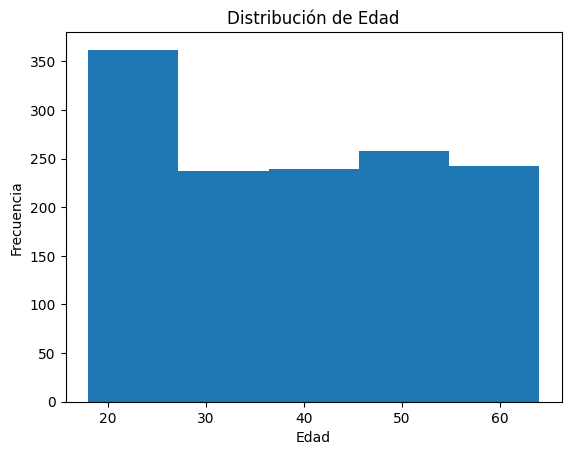

In [74]:
edad = df['age']

plt.hist(edad, bins=5)
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Distribución de Edad')
plt.show()

Vemos que los datos son bastante lineales en cuanto a la edad. Siendo la edad máxima 64 años, nos cuadra que la media esté en los 39 (más o menos a la mitad)

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_numpy` loads all data into the driver's memory. It should only be used if the resulting NumPy ndarray is expected to be small.



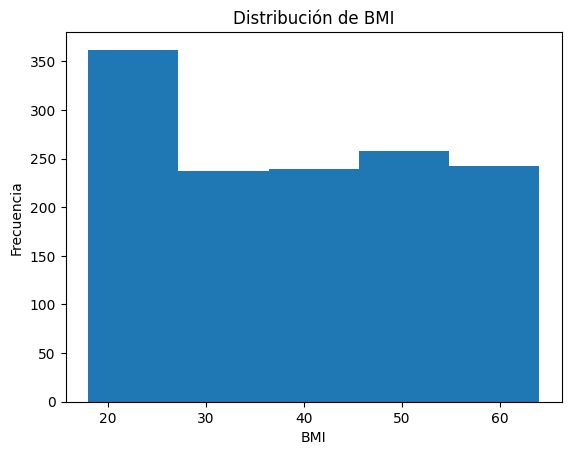

In [75]:
bmi = df['bmi']

plt.hist(edad, bins=5)
plt.xlabel('BMI')
plt.ylabel('Frecuencia')
plt.title('Distribución de BMI')
plt.show()

Vemos que los datos de BMI también están bastante repartidos

In [76]:
df['children'].value_counts().plot(kind='pie')

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/base.py:1437: FutureWarning:

The resulting Series will have a fixed name of 'count' from 4.0.0.



Aquí podemos ver que la gran mayoría de personas tienen 0 o un hijo.

In [77]:
df['sex'].value_counts().plot(kind='pie')

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/base.py:1437: FutureWarning:

The resulting Series will have a fixed name of 'count' from 4.0.0.



La variable sexo también está muy repartida.

In [78]:
df['smoker'].value_counts().plot(kind='pie')

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/base.py:1437: FutureWarning:

The resulting Series will have a fixed name of 'count' from 4.0.0.



Aquí vemos que la mayoría de la muestra es no fumadora.

In [79]:
df['region'].value_counts().plot(kind='pie')

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/base.py:1437: FutureWarning:

The resulting Series will have a fixed name of 'count' from 4.0.0.



Los asegurados en su mayoría están muy repartidos en cuanto a las regiones.

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_numpy` loads all data into the driver's memory. It should only be used if the resulting NumPy ndarray is expected to be small.



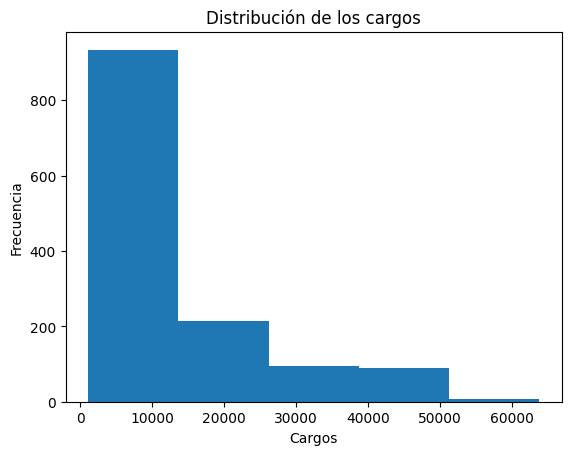

In [80]:
charges = df['charges']

plt.hist(charges, bins=5)
plt.xlabel('Cargos')
plt.ylabel('Frecuencia')
plt.title('Distribución de los cargos')
plt.show()

Vemos que la mayoria de los datos se concentran hasta las 12000 aproximadamente lo cual cuadra con la media.

#ANÁLISIS BIVARIANTE

Vamos a proceder a ver si existe relación entre variables.

In [81]:
df.groupby('sex')['charges'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64

Vemos que el sexo no influye en los costos

In [82]:
df.groupby('smoker')['charges'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

Aquí si vemos claramente que el hecho de ser fumador influye directamente en los costes.

In [83]:
df.groupby('region')['charges'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



region
northwest    12417.575374
southeast    14735.411438
northeast    13406.384516
southwest    12346.937377
Name: charges, dtype: float64

La región no es una variable que influya en los costos. Los datos están muy repartidos.

In [84]:
df.groupby('children')['charges'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



children
1    12731.171832
3    15355.318367
5     8786.035247
4    13850.656311
2    15073.563734
0    12365.975602
Name: charges, dtype: float64

El hecho de tener más o menos hijos no parece excesivamente relevante.

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



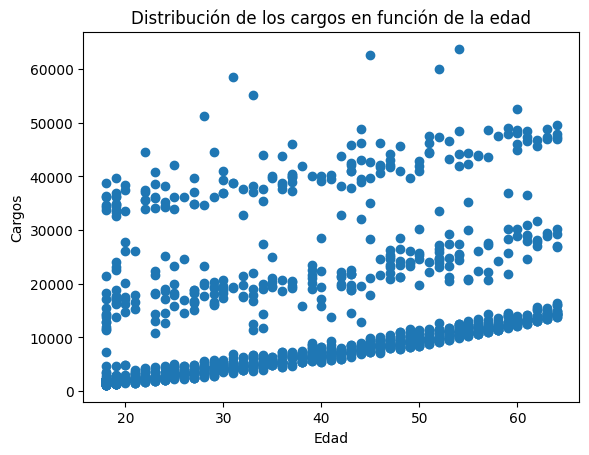

In [85]:
pdf = df[['age', 'charges']].to_pandas()#tenemos que pasarlo a un dataframe de pandas para poder graficar
plt.scatter(pdf['age'], pdf['charges'])
plt.xlabel('Edad')
plt.ylabel('Cargos')
plt.title('Distribución de los cargos en función de la edad')
plt.show()

Vemos claramente que la edad es muy determinante en los cargos. Según aumenta la edad, aumentan los cargos.

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



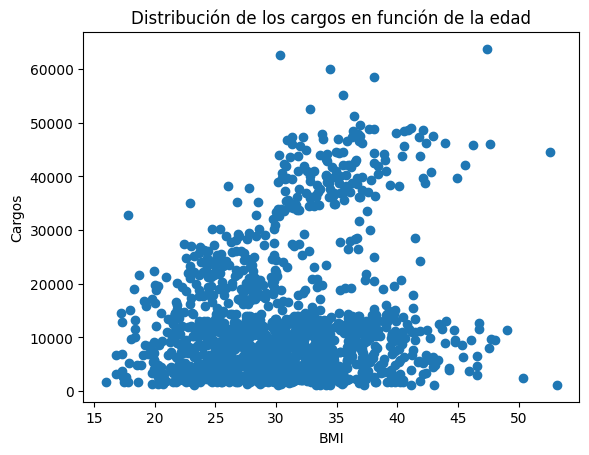

In [86]:
pdf = df[['bmi', 'charges']].to_pandas()#tenemos que pasarlo a un dataframe de pandas para poder graficar
plt.scatter(pdf['bmi'], pdf['charges'])
plt.xlabel('BMI')
plt.ylabel('Cargos')
plt.title('Distribución de los cargos en función de la edad')
plt.show()

Aquí podemos ver claramente que los datos más elevados de cargos se dan cuando el BMI aumenta. Tiene sentido. Cuanto mayor BMI tenemos, menor calidad de vidad y por ende, mayor probabilidad de gasto.

Por lo tanto podemos decir que el BMI, la edad y el hecho de ser fumador o no son determinantes. Vamos a profundizar en estas variables.

In [87]:
df.groupby('sex')['bmi'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



sex
female    30.377749
male      30.943129
Name: bmi, dtype: float64

In [88]:
df.groupby('smoker')['bmi'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



smoker
no     30.651795
yes    30.708449
Name: bmi, dtype: float64

In [89]:
df.groupby('region')['bmi'].mean()


/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



region
northwest    29.199785
southeast    33.355989
northeast    29.173503
southwest    30.596615
Name: bmi, dtype: float64

In [90]:
df.groupby('children')['bmi'].mean()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/groupby.py:649: FutureWarning:

Default value of `numeric_only` will be changed to `False` instead of `True` in 4.0.0.



children
1    30.623148
3    30.684331
5    29.605000
4    31.391200
2    30.978104
0    30.550296
Name: bmi, dtype: float64

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



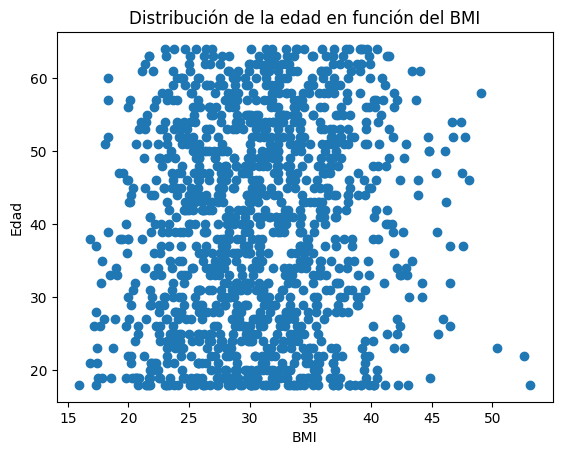

In [91]:
pdf = df[['bmi', 'age']].to_pandas()#tenemos que pasarlo a un dataframe de pandas para poder graficar
plt.scatter(pdf['bmi'], pdf['age'])
plt.xlabel('BMI')
plt.ylabel('Edad')
plt.title('Distribución de la edad en función del BMI')
plt.show()

No vemos nada destacable que añadir en el BMI. Vamos con la siguiente variable (fumador)

In [92]:
df.groupby('sex')['smoker'].count()

sex
female    662
male      676
Name: smoker, dtype: int64

In [93]:
df.groupby('children')['smoker'].count()

children
1    324
3    157
5     18
4     25
2    240
0    574
Name: smoker, dtype: int64

In [94]:
df.groupby('region')['smoker'].count()

region
northwest    325
southeast    364
northeast    324
southwest    325
Name: smoker, dtype: int64

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



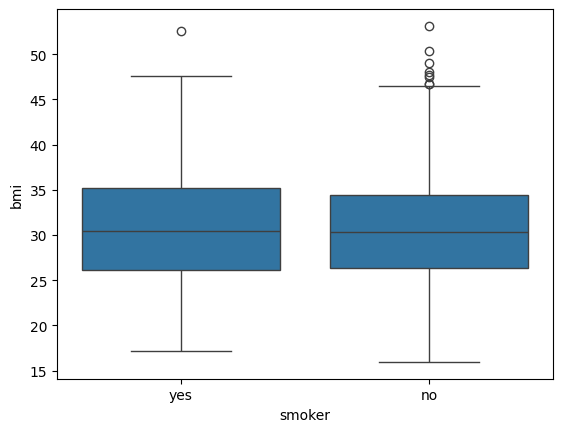

In [95]:
pdf = df[['smoker', 'bmi']].to_pandas()
sns.boxplot(x=pdf['smoker'], y=pdf['bmi'])
plt.show()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



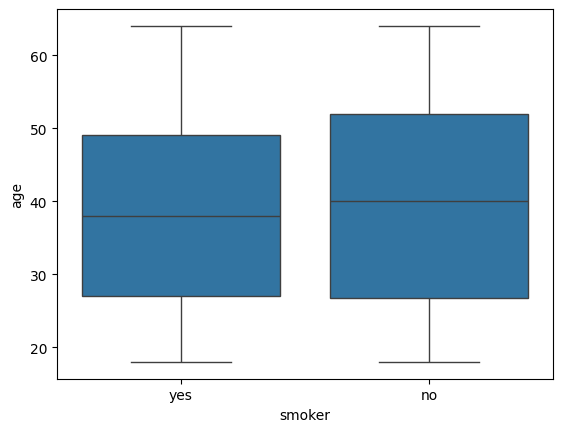

In [96]:
pdf = df[['smoker', 'age']].to_pandas()
sns.boxplot(x=pdf['smoker'], y=pdf['age'])
plt.show()

Nada reseñable que añadir para los fumadores. Vayamos con la edad.

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



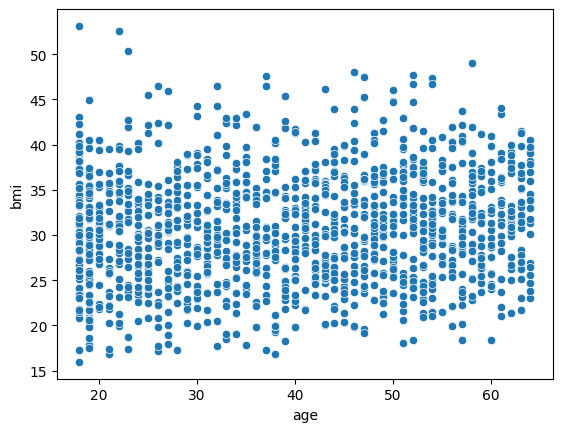

In [97]:
pdf = df[['age', 'bmi']].to_pandas()
sns.scatterplot(data=pdf, x='age', y='bmi')
plt.show()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



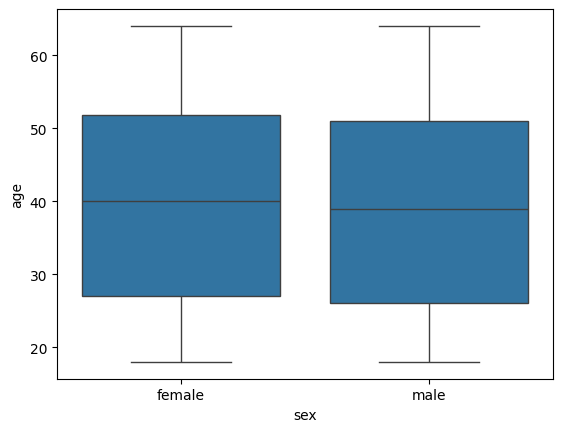

In [98]:
pdf = df[['sex', 'age']].to_pandas()
sns.boxplot(x=pdf['sex'], y=pdf['age'])
plt.show()

/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

`to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.



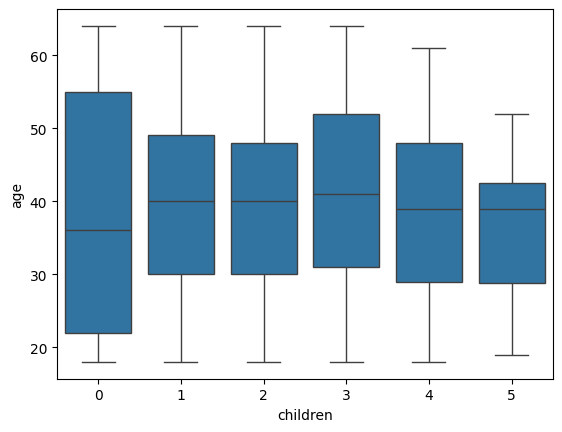

In [99]:
pdf = df[['children', 'age']].to_pandas()
sns.boxplot(x=pdf['children'], y=pdf['age'])
plt.show()

Vemos que en edad no hay nada relevante.

De cara al modelo de regresión por tanto tendremos en cuenta para la predicción: BMI, edad y fumador.

#REGRESIÓN LINEAL.

Luego conviertelós a un DataFrame de Spark normal, realiza las conversiones necesarias para poder hacer machine learning (StringIndexer, StandardScaler, VectorAssembler...) y aplica un modelo de regresión lineal usando pyspark.ml

In [100]:
spark_df= df.to_spark()
spark_df.printSchema()

root
 |-- age: integer (nullable = true)
 |-- sex: string (nullable = true)
 |-- bmi: double (nullable = true)
 |-- children: integer (nullable = true)
 |-- smoker: string (nullable = true)
 |-- region: string (nullable = true)
 |-- charges: double (nullable = true)



/usr/local/lib/python3.11/dist-packages/pyspark/pandas/utils.py:1016: PandasAPIOnSparkAdviceWarning:

If `index_col` is not specified for `to_spark`, the existing index is lost when converting to Spark DataFrame.



Recordemos que las tres variables que nos ayudaran a predecir serán bmi, edad y smoker. Las dos primeras son numéricas. Utilizamos string indexer para etiquetar smoker.

In [101]:
label_indexer = StringIndexer(inputCol="smoker", outputCol="smoker_label")
label_model = label_indexer.fit(spark_df)
spark_df = label_model.transform(spark_df)

In [102]:
spark_df.show(5)

+---+------+------+--------+------+---------+-----------+------------+
|age|   sex|   bmi|children|smoker|   region|    charges|smoker_label|
+---+------+------+--------+------+---------+-----------+------------+
| 19|female|  27.9|       0|   yes|southwest|  16884.924|         1.0|
| 18|  male| 33.77|       1|    no|southeast|  1725.5523|         0.0|
| 28|  male|  33.0|       3|    no|southeast|   4449.462|         0.0|
| 33|  male|22.705|       0|    no|northwest|21984.47061|         0.0|
| 32|  male| 28.88|       0|    no|northwest|  3866.8552|         0.0|
+---+------+------+--------+------+---------+-----------+------------+
only showing top 5 rows



Ahora usaremos OneHotEncoder.(realmente no seria necesario ya que fumador es si o no como opciones aunque lo usamos a modo práctica)

In [103]:
encoder = OneHotEncoder(inputCol="smoker_label", outputCol="smoker_vec")
encoder_model = encoder.fit(spark_df)
spark_df = encoder_model.transform(spark_df)

In [104]:
spark_df.show(5)

+---+------+------+--------+------+---------+-----------+------------+-------------+
|age|   sex|   bmi|children|smoker|   region|    charges|smoker_label|   smoker_vec|
+---+------+------+--------+------+---------+-----------+------------+-------------+
| 19|female|  27.9|       0|   yes|southwest|  16884.924|         1.0|    (1,[],[])|
| 18|  male| 33.77|       1|    no|southeast|  1725.5523|         0.0|(1,[0],[1.0])|
| 28|  male|  33.0|       3|    no|southeast|   4449.462|         0.0|(1,[0],[1.0])|
| 33|  male|22.705|       0|    no|northwest|21984.47061|         0.0|(1,[0],[1.0])|
| 32|  male| 28.88|       0|    no|northwest|  3866.8552|         0.0|(1,[0],[1.0])|
+---+------+------+--------+------+---------+-----------+------------+-------------+
only showing top 5 rows



A continuación usaremos Vector Asembler para crear la columna Features teniendo en cuenta las variables que usaremos para predecir.

In [105]:
assembler = VectorAssembler(inputCols=["age", "bmi", "smoker_vec"],outputCol="features")
spark_df = assembler.transform(spark_df)

In [106]:
spark_df.show()

+---+------+------+--------+------+---------+-----------+------------+-------------+-----------------+
|age|   sex|   bmi|children|smoker|   region|    charges|smoker_label|   smoker_vec|         features|
+---+------+------+--------+------+---------+-----------+------------+-------------+-----------------+
| 19|female|  27.9|       0|   yes|southwest|  16884.924|         1.0|    (1,[],[])|  [19.0,27.9,0.0]|
| 18|  male| 33.77|       1|    no|southeast|  1725.5523|         0.0|(1,[0],[1.0])| [18.0,33.77,1.0]|
| 28|  male|  33.0|       3|    no|southeast|   4449.462|         0.0|(1,[0],[1.0])|  [28.0,33.0,1.0]|
| 33|  male|22.705|       0|    no|northwest|21984.47061|         0.0|(1,[0],[1.0])|[33.0,22.705,1.0]|
| 32|  male| 28.88|       0|    no|northwest|  3866.8552|         0.0|(1,[0],[1.0])| [32.0,28.88,1.0]|
| 31|female| 25.74|       0|    no|southeast|  3756.6216|         0.0|(1,[0],[1.0])| [31.0,25.74,1.0]|
| 46|female| 33.44|       1|    no|southeast|  8240.5896|         0.0|(1,

Aplicamos regresión lineal

In [152]:
train_data, test_data = spark_df.randomSplit([0.8, 0.2], seed=13)

In [153]:
lr = LinearRegression(featuresCol="features", labelCol="charges")

In [154]:
paramGrid = (ParamGridBuilder()
             .addGrid(lr.regParam, [0.01, 0.5, 2.0])
             .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
             .addGrid(lr.maxIter, [1, 5, 10])
             .build())

In [155]:
evaluator = RegressionEvaluator(labelCol="charges",predictionCol="prediction",metricName="mae")

In [156]:
crossval = CrossValidator(estimator=lr,
                          estimatorParamMaps=paramGrid,
                          evaluator=evaluator,
                          numFolds=2)

In [157]:
cvmodel = crossval.fit(train_data)

In [158]:
prediction = cvmodel.transform(test_data)

Evaluamos los resultados

In [159]:
mae = evaluator.evaluate(prediction)
print("MAE:", mae)

MAE: 4330.315774579721


Utilizamos MAE ya que nos dice el promedio de las diferencias absolutas entre predicción y valor real. Nuestro modelo falla 4330 euros de media. Teniendo en cuenta que nuestra media ronda los 13000 estaríamos hablando de un 30% de error. Quizás necesitaríamos otras variables o utilizar otro tipo de modelo.Vamos a probar con Random Forest.

In [160]:
train_data, test_data = spark_df.randomSplit([0.8, 0.2], seed=3)

In [161]:
rf = RandomForestRegressor(featuresCol="features", labelCol="charges", predictionCol="prediction")

In [162]:
paramGrid = (ParamGridBuilder()
             .addGrid(rf.numTrees, [10, 50, 100])
             .addGrid(rf.maxDepth, [5, 10, 20])
             .build())#cambiamos los parametros. son diferentes de los de linear regresion.

In [163]:
evaluator_rf = RegressionEvaluator(labelCol="charges",predictionCol="prediction",metricName="mae")

In [164]:
crossval = CrossValidator(estimator=rf,
                          estimatorParamMaps=paramGrid,
                          evaluator=evaluator_rf,
                          numFolds=2)

In [165]:
cvmodel = crossval.fit(train_data)

In [166]:
prediction = cvmodel.transform(test_data)

In [167]:
mae = evaluator.evaluate(prediction)

print(f"MAE: {mae}")

MAE: 3036.125048411121


Vemos que de media Random Forest se equivoca menos el modelo de regresión lineal. El margen de error es casi 300 unidades más bajas por lo que optariamos más por este modelo.